# Numerical Solution of the Blasius Boundary - Value Problem
## Anchal Bhupal
## SC26M006

## 1. Aim
This assignment aims to obtain a numerical solution of the Blasius equation for laminar flow over a flat plate. The boundary-value problem is solved by converting it into an Initial-Value Problem using the shooting method. We implement third- and fourth-order Runge-Kutta schemes and examine their accuracy for different step sizes.

## 2. Governing equation and Boundary conditions
The similarity form of the Blasius equation is:
$$f''' + \frac{1}{2}ff'' = 0, \, 0 \leq \eta < \infty.$$
The boundary conditions are:
$$f(0)=0, f'(0)=0, f'(\infty)=1.$$
The first two conditions represent no penetration and no slip at the plate. The last condition requires the velocity to approach the free-stream value away from the wall. In the numerical calculation, infinity is represented by a sufficiently large finite value, chosen here as $\eta_{max}=10$.

## 3. Conversion into a first-order system
Introduce three dependent variables:
$$Y_1 = f, Y_2 = f', Y_3 = f'' .$$
Differentiating these definitions and using the governing equation gives:
$$Y'_1 = Y_2, Y'_2 = Y_3, Y'_3 = - \frac{1}{2}Y_1 Y_3$$
Therefore,
$$\frac{d \mathbf{Y}}{d\eta} = \mathbf{G(Y)} = \begin{bmatrix}Y_2\\Y_3\\-\frac{1}{2}Y_1 Y_3 \end{bmatrix}$$
At the wall, $Y_1(0)=0$ and $Y_2(0)=0$ are known, but $Y_3(0)=f''(0)$ is not specified. We denote this unknown initial curvature by $s$, so the initial state becomes $\mathbf{Y}(0)=[0,0,s]^T$

## 4. Shooting method 
A trial value of $s$ makes the problem an initial value problem. The system is integrated from $\eta = 0$ to $\eta = 10$, and the computed terminal slope is compared with the required value of one. We define:
$$R(s) = f'(10;s)-1$$
The required value of $s$ is the root of $R(s)=0$. Bisection is used because the residual changes sign over the initial bracket $[0.2, 0.4]$.\\
The midpoint is evaluated repeatedly; the half interval containing the sign change is retained until the interval width or residual is sufficiently small.

## 5. Numerical integration
### 5.1 Third-order Runge-Kutta method
For a system $Y' = G(Y)$, the third-order scheme used is: 
$$K_1 = hG(Y_n),$$
$$K_2 = hG(Y_n + K_1/2),$$
$$K_3 = hG(Y_n - K_1 +2K_2),$$
$$Y_{n+1} = Y_n + \frac{K_1 + 4K_2 + K_3}{6} .$$

### 5.2 Fourth-order Runge-Kutta method
The typical fourth-order scheme is:
$$K_1 = hG(Y_N),$$
$$K_2 = hG(Y_n + K_1/2),$$
$$K_3 = hG(Y_n + K_2/2),$$
$$K_4 = hG(Y_n + K_3)$$
$$Y_{n+1} = Y_n + \frac{K_1 + 2K_2 + 2K-3 + K_4}{6} .$$

The expected global errors are proportional to $h^3$ for RK3 and $h^4$ for RK4, before round-off and other error sources become significant.

In [1]:
#Defining functions and parameters

import numpy as np
import matplotlib.pyplot as plt

eta_max = 10.0
step_sizes = [0.4, 0.2, 0.1, 0.05, 0.025]
reference_s =0.3320573362

# Blasius differential equation
def G(Y):
    f ,fp, fpp =Y
    return np.array([fp, fpp, -0.5*f*fpp], dtype=float)

def integrate_ivp(s, h, method, save_history=False):
    n=int(round(eta_max/h))
    h= eta_max/n
    Y=np.array([0.0,0.0,s])
    history = [Y.copy()]

    for i in range(n):
        K1 = h*G(Y)
        if method=="RK3":
            K2 = h*G(Y+K1/2)
            K3 = h*G(Y- K1 + 2*K2)
            Y=Y+(K1+4*K2+K3)/6
        elif method == "RK4":
            K2=h*G(Y+K1/2)
            K3=h*G(Y+K2/2)
            K4=h*G(Y + K3)
            Y=Y+(K1+2*K2+2*K3+K4)/6
        else:
            raise ValueError("Choose RK3 or RK4.")
        history.append(Y.copy())

    if save_history:
        eta = np.linspace(0.0, eta_max, n+1)
        return eta, np.asarray(history)
            
    return Y

def terminal_residual(s, h, method):
    return integrate_ivp(s,h, method)[1]-1.0

def find_shooting_parameter(h,  method, lower=0.2, upper=0.4, tol=1e-12):
    a, b = lower, upper
    fa = terminal_residual(a, h, method)
    fb = terminal_residual(b,h , method)
    if fa*fb>0:
        raise ValueError("The initial interval does not bracket a root.")

    for i in range(100):
        mid = 0.5*(a+b)
        fm = terminal_residual(mid, h, method)

        if abs(fm)<tol or 0.5*(b-a) < tol:
            return mid
        if fa*fm<0:
            b, fb = mid, fm
        else:
            a, fa = mid, fm
    return 0.5*(a+b)

## 6. Third-order Runge-Kutta solution and results

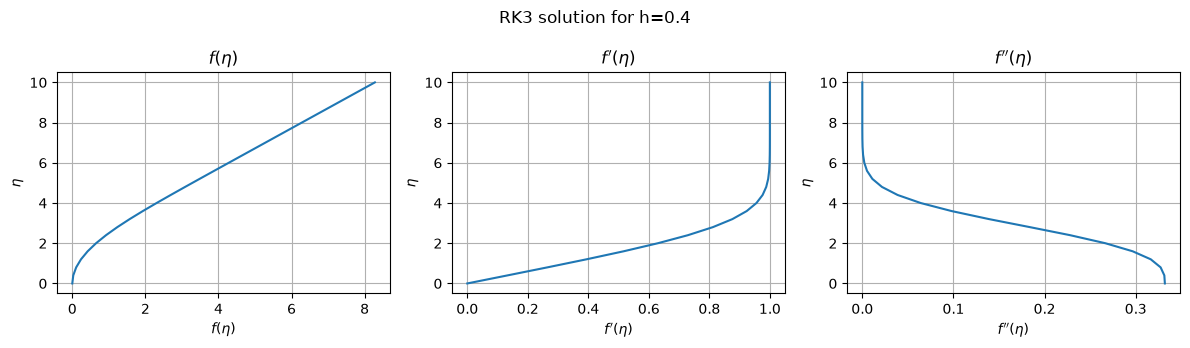

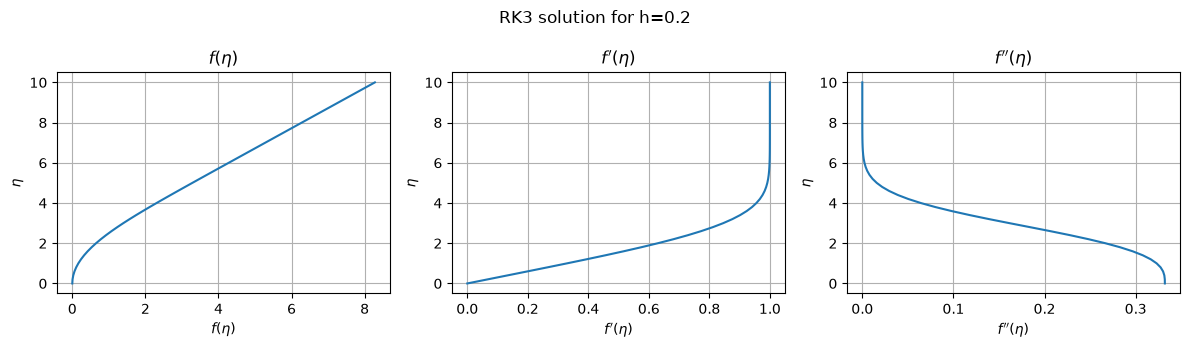

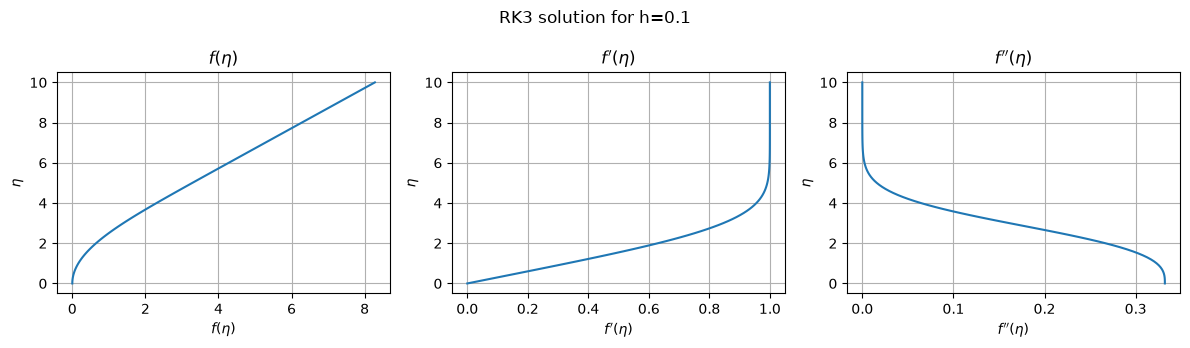

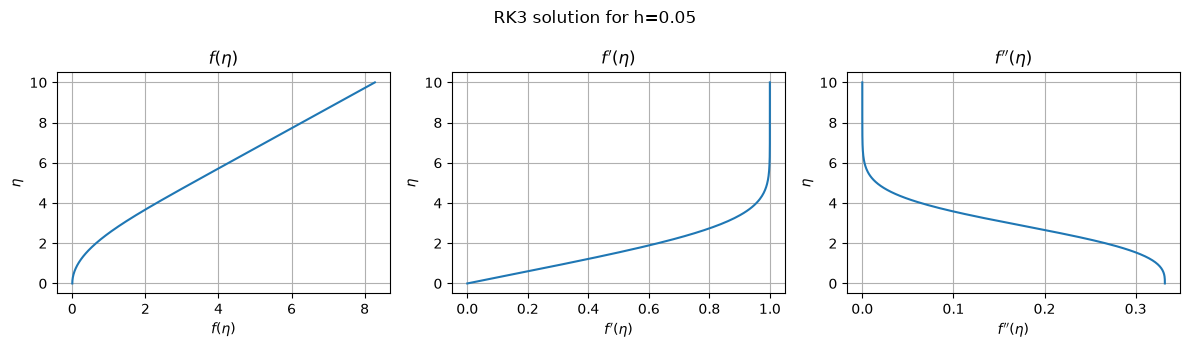

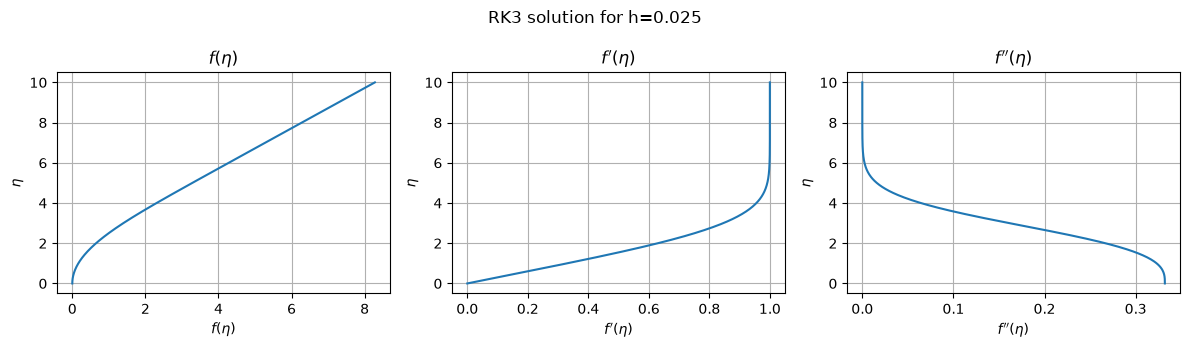

Step sizes: [0.4, 0.2, 0.1, 0.05, 0.025]
Rk3 shooting parameters:  [0.3319771447699168, 0.33204959824870467, 0.3320565334011918, 0.33205724759172883, 0.33205732670103333]
Absolute errors: [8.019143008319851e-05, 7.73795129532795e-06, 8.02798808208216e-07, 8.860827116485837e-08, 9.498966668797237e-09]
Observed Orders:  [3.37342451 3.26884127 3.1795252  3.22159889]


In [2]:
rk3_s= []
rk3_error = []

labels = [r"$f(\eta)$", r"$f'(\eta)$", r"$f''(\eta)$"]

for h in step_sizes:
    s = find_shooting_parameter(h, "RK3") # ---> gives shooting parameter
    
    rk3_s.append(s)
    rk3_error.append(abs(s-reference_s))

    #integrate the blasius equations
    eta, Y = integrate_ivp(s, h, "RK3", True)
    
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
    for j in range(3):
        ax[j].plot(Y[:,j], eta)
        ax[j].set_xlabel(labels[j])
        ax[j].set_ylabel(r"$\eta$")
        ax[j].grid(True)
        ax[j].set_title(labels[j])
    plt.suptitle(f"RK3 solution for h={h}")
    plt.tight_layout()
    plt.show()

rk3_order = np.log(np.array(rk3_error[:-1])/np.array(rk3_error[1:]))/np.log(2)
print("Step sizes:", step_sizes)
print("Rk3 shooting parameters: ", rk3_s)
print("Absolute errors:", rk3_error)
print("Observed Orders: ", rk3_order)

## 7. Fourth-Order Runge-Kutta Solution and Result
The Blasius equation is solved using the fourth-order Runge-Kutta (RK4) method combined with the shooting method. The unknown initial value $f''(0)$ is determined using the **bisection method**. The calculations are repeated for different step sizes, and the shooting parameters and errors are analysed to evaluate the accuracy and convergence of RK4.


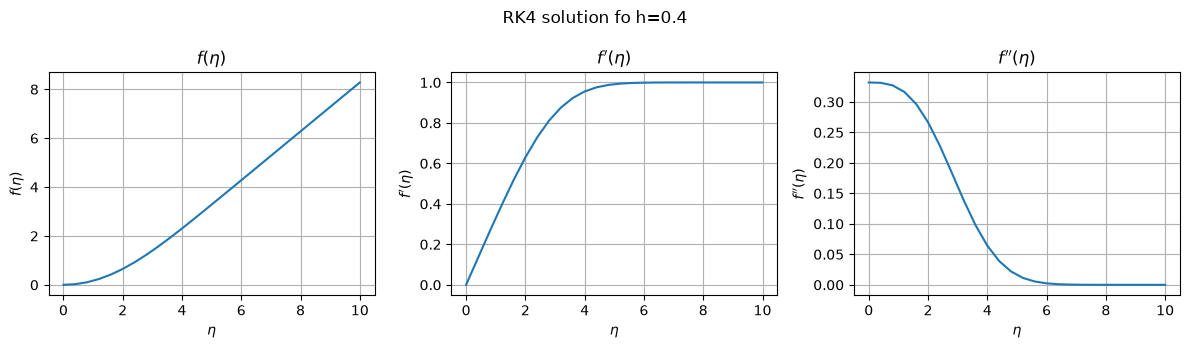

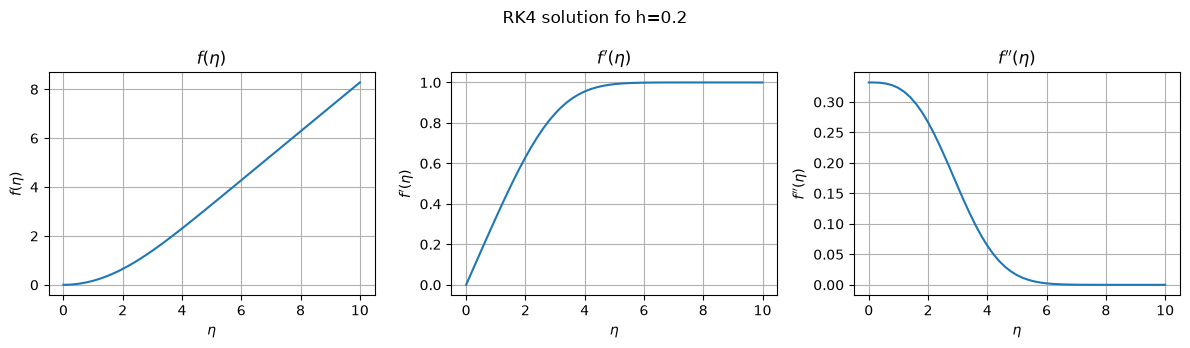

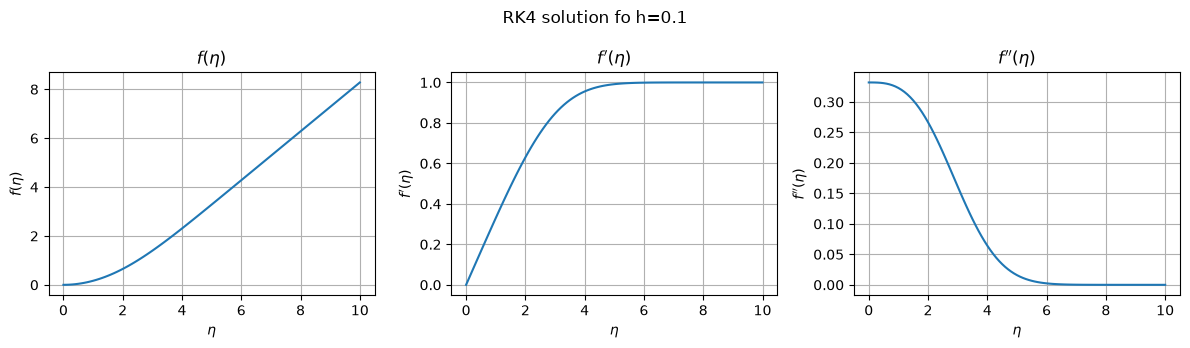

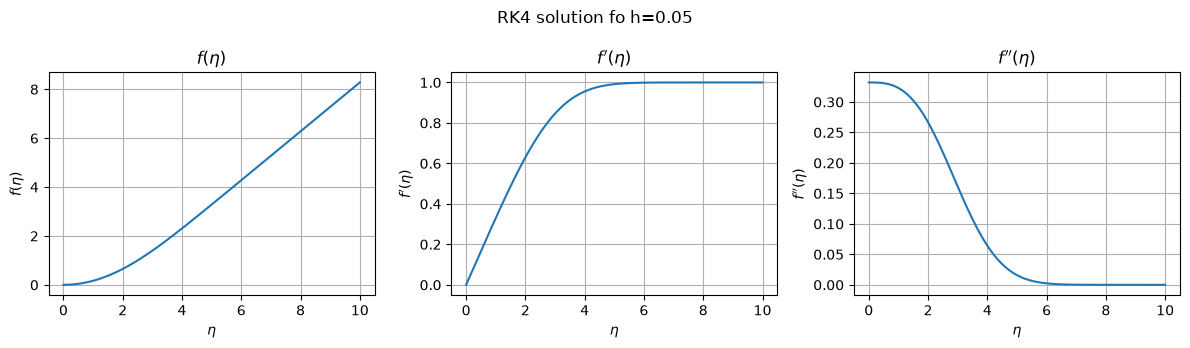

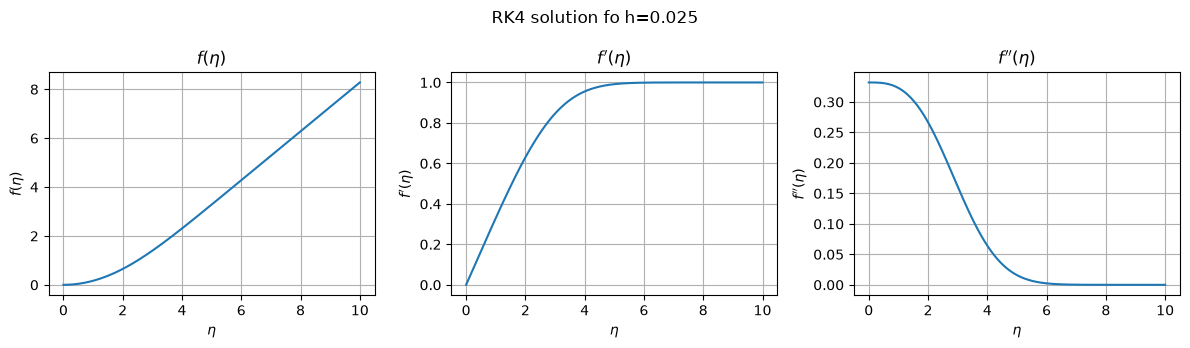

Step sizes: [0.4, 0.2, 0.1, 0.05, 0.025]
RK4 shooting parameters: [0.33205881583926394, 0.33205745745071913, 0.33205734561051947, 0.33205733775685076, 0.3320573372388026]
Absolute errors: [1.4796392639460088e-06, 1.212507191317158e-07, 9.410519474783996e-09, 1.5568507594210246e-09, 1.0388025994956251e-09]
Observed orders: [3.60918028 3.68757513 2.59564371 0.58370912]


In [4]:
rk4_s = []
rk4_error = []
for h in step_sizes:
    s = find_shooting_parameter(h, "RK4")
    rk4_s.append(s)
    rk4_error.append(abs(s-reference_s))

    #integrating the Blasius equation
    eta, Y = integrate_ivp(s, h, "RK4", True)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
    for j in range(3):
        ax[j].plot(eta, Y[:, j])
        ax[j].set_xlabel(r"$\eta$")
        ax[j].set_ylabel(labels[j])
        ax[j].grid(True)
        ax[j].set_title(labels[j])
    plt.suptitle(f"RK4 solution fo h={h}")
    plt.tight_layout()
    plt.show()

rk4_order = np.log(np.array(rk4_error[:-1])/np.array(rk4_error[1:]))/np.log(2)
print("Step sizes:", step_sizes)
print("RK4 shooting parameters:", rk4_s)
print("Absolute errors:", rk4_error)
print("Observed orders:", rk4_order)

## 8. Grid refinement and convergence
The accuracy of the numerical solution is examined by performing grid refinement using different step sizes. The shooting parameter $s=f''(0)$ obtained for each step size is compared with the accepted reference value.

The absolute error in the shooting parameter is calculated as:
$$E(h)=|s_h-s_{\mathrm{ref}}|$$
where $s_h$ is the shooting parameter obtained numerically for a given step size $h$, and
$$s_{\mathrm{ref}}=0.3320573362$$
is the accepted reference value.

The observed order of convergence between two successive step sizes is estimated using:
$$p_i=\frac{\log\left(E(h_i)/E(h_{i+1})\right)}{\log\left(h_i/h_{i+1}\right)}$$

A log-log plot of absolute error against step size is used to examine the convergence behaviour. If the error varies approximately as $E(h)\propto h^p$, the slope of the graph represents the order of convergence $p$.

The convergence behaviour of RK3 and RK4 is examined separately in the following sections.

### 8.1 RK3 Grid refinement and convergence
The RK3 method is studied using different step sizes to examine how the numerical error changes with grid refinement. The absolute errors and observed orders calculated earlier are used to evaluate its convergence behaviour.

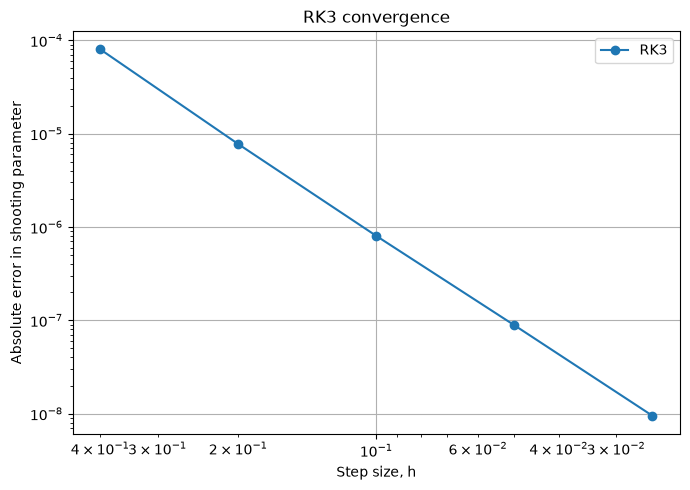

RK3 shooting parameters: [0.3319771447699168, 0.33204959824870467, 0.3320565334011918, 0.33205724759172883, 0.33205732670103333]
RK3 absolute errors: [8.019143008319851e-05, 7.73795129532795e-06, 8.02798808208216e-07, 8.860827116485837e-08, 9.498966668797237e-09]
RK3 observed orders: [3.37342451 3.26884127 3.1795252  3.22159889]


In [5]:
# RK3 convergence plot

plt.figure(figsize=(7, 5))
plt.loglog(step_sizes, rk3_error, "o-", label="RK3")

plt.xlabel("Step size, h")
plt.ylabel("Absolute error in shooting parameter")
plt.title("RK3 convergence")
plt.grid(True)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

print("RK3 shooting parameters:", rk3_s)
print("RK3 absolute errors:", rk3_error)
print("RK3 observed orders:", rk3_order)


**Observation:** \
As the step size decreases, the absolute error in the RK3 shooting parameter decreases. This indicates that the numerical solution becomes more accurate with grid refinement. The observed orders are used to examine whether the method approaches its expected third-order convergence behaviour.

### 8.2 RK4 Grid refinement and convergence
The same grid refinement study is performed using the RK4 method. The shooting parameters obtained for different step sizes are compared with the accepted reference value, and the corresponding absolute errors and observed orders are examined.

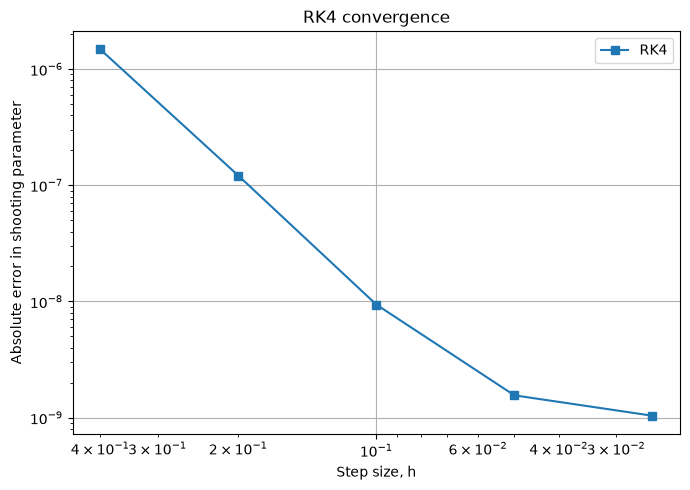

RK4 shooting parameters: [0.33205881583926394, 0.33205745745071913, 0.33205734561051947, 0.33205733775685076, 0.3320573372388026]
RK4 absolute errors: [1.4796392639460088e-06, 1.212507191317158e-07, 9.410519474783996e-09, 1.5568507594210246e-09, 1.0388025994956251e-09]
RK4 observed orders: [3.60918028 3.68757513 2.59564371 0.58370912]


In [6]:
# RK4 convergence plot
plt.figure(figsize=(7, 5))
plt.loglog(step_sizes, rk4_error, "s-", label="RK4")

plt.xlabel("Step size, h")
plt.ylabel("Absolute error in shooting parameter")
plt.title("RK4 convergence")
plt.grid(True)
plt.legend()
plt.gca().invert_xaxis()

plt.tight_layout()
plt.show()

print("RK4 shooting parameters:", rk4_s)
print("RK4 absolute errors:", rk4_error)
print("RK4 observed orders:", rk4_order)


**Observation**:\
The RK4 absolute error decreases as the step size is reduced from $(h=0.4)$ to $(h=0.05)$, indicating improved accuracy with grid refinement. The observed orders for the first three refinements are approximately 3.61, 3.69 and 2.60, showing convergence behaviour close to the expected fourth order initially.

However, when the step size is further reduced from $(h=0.05)$ to $(h=0.025)$, the observed order drops to approximately 0.58. This indicates that the error reduction becomes much smaller at finer grids. RK4 provides good accuracy, but its observed convergence rate is not maintained at the finest step sizes.

### 8.3 Comparison of RK3 and RK4


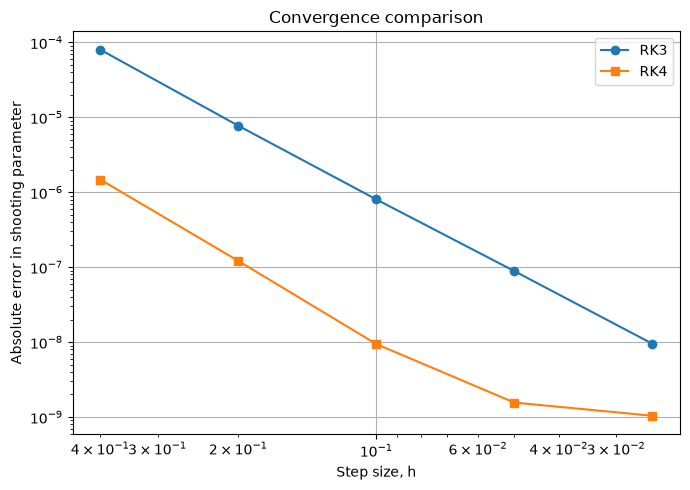

RK3 observed orders: [3.37342451 3.26884127 3.1795252  3.22159889]
RK4 observed orders: [3.60918028 3.68757513 2.59564371 0.58370912]


In [7]:
plt.figure(figsize=(7, 5))
plt.loglog(step_sizes, rk3_error, "o-", label="RK3")
plt.loglog(step_sizes, rk4_error, "s-", label="RK4")
plt.xlabel("Step size, h")
plt.ylabel("Absolute error in shooting parameter")
plt.title("Convergence comparison")
plt.grid(True)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

print("RK3 observed orders:", rk3_order)
print("RK4 observed orders:", rk4_order)

**Observation:**\
The comparison shows that RK4 generally produces smaller errors than RK3 for the same step size. This is consistent with the higher order of accuracy of RK4. Both methods show improved accuracy with grid refinement, although the observed convergence rates can be affected by numerical precision at smaller step sizes.

## 9. Discussion
For both methods, the computed shooting parameter approaches approximately $0.3321$ as the step size is reduced. This agrees with the accepted Blasius wall-curvature value to three decimal places. The velocity profile $f'(\eta)$ starts from zero at the wall and approaches one away from the plate, satisfying the physical boundary conditions. The curvature $f''(\eta)$ decreases with distance from the wall.

The RK3 errors decrease consistently with refinement, and the observed orders are close to three. For RK4, the coarser refinements show a trend toward fourth-order behaviour, but the finest-grid errors approach a numerical floor, and the measured order becomes unreliable. This is expected when truncation error becomes comparable to floating-point, root-finding, and finite-domain errors. Therefore, the formal order of RK4 is fourth order, but the computed order should be interpreted only over the range where the error decreases cleanly.

## 10. Conclusion
The Blasius boundary-value problem was solved by converting it into a first-order system and applying the shooting method. Bisection was used to estimate the unknown wall curvature, while RK3 and RK4 were used for integration. The resulting value of $f''(0)$ is approximately $0.332$, and the computed profiles satisfy the imposed wall and far-field conditions. Grid refinement confirms the expected third-order trend for RK3. RK4 is more accurate on the coarser grids, although its finest-grid error is affected by numerical error saturation. The exercise demonstrates how a boundary-value problem can be handled using initial-value solvers and a scalar root-finding method.